## 1. Import Library & Konfigurasi Lingkungan
Pada tahap ini diimpor semua pustaka Python yang dibutuhkan untuk manipulasi data, visualisasi, dan pra-pemrosesan.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# Konfigurasi gaya visualisasi visual
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100
print("Library berhasil dimuat!")

Library berhasil dimuat!


## 2. Pemuatan Dataset (Data Loading) & Inspeksi Awal
Dataset yang digunakan adalah data riwayat rekam medis (EMR) yang berisi atribut kunjungan pasien meliputi diagnosa, institusi penjamin/asal, area/wilayah, rumah sakit/klinik, tipe pelayanan, dan kategori biaya berobat.

In [14]:
# Contoh pemuatan file dataset:
# Anda dapat mengunggah file 'IP___Riwayat_Medical_01012016 s.d 19032024 - Copy.xls' or 'dataset.xls'
file_path = 'dataset.xls'  # Sesuaikan dengan path file di lingkungan Colab Anda

try:
    df = pd.read_excel(file_path)
    print(f"Dataset berhasil dimuat! Dimensi: {df.shape[0]} baris, {df.shape[1]} kolom.")
except Exception as e:
    print("File lokal belum ditemukan. Menyiapkan simulasi struktur dataset EMR sesuai modul acuan...")
    # Simulasi data representatif EMR sesuai modul praktikum Pak Ryan Putranda Kristianto
    np.random.seed(42)
    n = 1000
    diagnosa_list = ['ISPA', 'Hipertensi', 'Dispepsia', 'Diabetes Mellitus', 'Myalgia', 'Cephalgia', 'Faringitis', 'Gastritis']
    institusi_list = ['Institusi A', 'Institusi B', 'Institusi C', 'Mandiri / Umum', 'BPJS Kesehatan']
    area_list = ['Surabaya Timur', 'Surabaya Barat', 'Surabaya Selatan', 'Surabaya Utara', 'Sidoarjo']
    rumah_list = ['RS Darmo', 'RS RKZ', 'RS Siloam', 'Klinik Pratama 1', 'Klinik Pratama 2']
    tipe_list = ['Rawat Jalan', 'Rawat Inap', 'UGD']
    biaya_list = ['Rendah (<500rb)', 'Sedang (500rb-2jt)', 'Tinggi (2jt-5jt)', 'Sangat Tinggi (>5jt)']

    df = pd.DataFrame({
        'no': np.arange(1, n + 1),
        'diagnosa': np.random.choice(diagnosa_list, n, p=[0.25, 0.20, 0.15, 0.12, 0.10, 0.08, 0.06, 0.04]),
        'institusi': np.random.choice(institusi_list, n, p=[0.30, 0.25, 0.20, 0.15, 0.10]),
        'area': np.random.choice(area_list, n, p=[0.28, 0.22, 0.20, 0.18, 0.12]),
        'rumah': np.random.choice(rumah_list, n, p=[0.30, 0.25, 0.20, 0.15, 0.10]),
        'tipe': np.random.choice(tipe_list, n, p=[0.75, 0.18, 0.07]),
        'biaya_berobat': np.random.choice(biaya_list, n, p=[0.45, 0.35, 0.14, 0.06])
    })

# Menampilkan 5 sampel teratas
df.head()

File lokal belum ditemukan. Menyiapkan simulasi struktur dataset EMR sesuai modul acuan...


,no,diagnosa,institusi,area,rumah,tipe,biaya_berobat
0,1,Hipertensi,Institusi A,Surabaya Timur,RS Siloam,Rawat Jalan,Rendah (<500rb)
1,2,Faringitis,Institusi B,Surabaya Timur,Klinik Pratama 1,Rawat Inap,Sedang (500rb-2jt)
2,3,Myalgia,Mandiri / Umum,Sidoarjo,RS Darmo,Rawat Inap,Tinggi (2jt-5jt)
3,4,Dispepsia,Institusi C,Surabaya Timur,RS Siloam,Rawat Jalan,Rendah (<500rb)
4,5,ISPA,Mandiri / Umum,Surabaya Timur,RS Siloam,Rawat Jalan,Tinggi (2jt-5jt)


In [3]:
# Memeriksa ringkasan tipe data dan keberadaan missing values
print("=== Ringkasan Tipe Data (dtypes) ===")
print(df.dtypes)
print("\n=== Pengecekan Nilai Kosong (Missing Values) ===")
print(df.isnull().sum())
print("\n=== Statistik Deskriptif Variabel ===")
df.describe(include='all')

=== Ringkasan Tipe Data (dtypes) ===
no                int64
diagnosa         object
institusi        object
area             object
rumah            object
tipe             object
biaya_berobat    object
dtype: object

=== Pengecekan Nilai Kosong (Missing Values) ===
no               0
diagnosa         0
institusi        0
area             0
rumah            0
tipe             0
biaya_berobat    0
dtype: int64

=== Statistik Deskriptif Variabel ===


,no,diagnosa,institusi,area,rumah,tipe,biaya_berobat
count,1000.000000,1000,1000,1000,1000,1000,1000
unique,NaN,8,5,5,5,3,4
top,NaN,ISPA,Institusi A,Surabaya Timur,RS Darmo,Rawat Jalan,Rendah (<500rb)
freq,NaN,269,296,268,315,762,456
mean,500.500000,NaN,NaN,NaN,NaN,NaN,NaN
std,288.819436,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,250.750000,NaN,NaN,NaN,NaN,NaN,NaN
50%,500.500000,NaN,NaN,NaN,NaN,NaN,NaN
75%,750.250000,NaN,NaN,NaN,NaN,NaN,NaN


```markdown
### Penjelasan & Insight Awal:
- **Struktur Data:** Dataset terdiri dari kolom identifier (`no`) serta serangkaian fitur kategorikal berupa teks: `diagnosa`, `institusi`, `area`, `rumah`, `tipe`, dan `biaya_berobat`.
- **Kualitas Data:** Tidak terdeteksi adanya nilai kosong (*null value*) pada dataset setelah tahap kurasi awal.
- **Kebutuhan Transformasi:** Mayoritas algoritma statistik dan data mining memerlukan representasi numerik. Oleh karena itu, fitur-fitur kategorikal harus ditransformasikan dengan teknik *Label Encoding*.
```

## 3. Data Cleaning & Preprocessing (Label Encoding)
Sesuai tahapan pada modul praktikum Pak Ryan Putranda Kristianto, setiap kolom bertipe *object/string* dienkode menjadi nilai integer menggunakan `LabelEncoder` dari Scikit-Learn.

In [4]:
# Inisialisasi DataFrame baru untuk hasil olah encoding
dataolahencoding = df.copy()

categorical_cols = ['diagnosa', 'institusi', 'area', 'rumah', 'tipe', 'biaya_berobat']
encoders = {}

for col in categorical_cols:
    if col in dataolahencoding.columns:
        le = LabelEncoder()
        # Pembuatan kolom baru berakhiran _encod
        dataolahencoding[f'{col}_encod'] = le.fit_transform(dataolahencoding[col].astype(str))
        encoders[col] = le
        print(f"Fitur '{col}' berhasil dienkode -> '{col}_encod' ({len(le.classes_)} kelas unik)")

# Menghapus kolom string asli dan kolom identifier 'no'
cols_to_drop = [col for col in categorical_cols if col in dataolahencoding.columns]
if 'no' in dataolahencoding.columns:
    cols_to_drop.append('no')

dataolahencoding.drop(columns=cols_to_drop, inplace=True)

print("\n=== Data Bersih Siap Analisis (dataolahencoding) ===")
dataolahencoding.head()

Fitur 'diagnosa' berhasil dienkode -> 'diagnosa_encod' (8 kelas unik)
Fitur 'institusi' berhasil dienkode -> 'institusi_encod' (5 kelas unik)
Fitur 'area' berhasil dienkode -> 'area_encod' (5 kelas unik)
Fitur 'rumah' berhasil dienkode -> 'rumah_encod' (5 kelas unik)
Fitur 'tipe' berhasil dienkode -> 'tipe_encod' (3 kelas unik)
Fitur 'biaya_berobat' berhasil dienkode -> 'biaya_berobat_encod' (4 kelas unik)

=== Data Bersih Siap Analisis (dataolahencoding) ===


,diagnosa_encod,institusi_encod,area_encod,rumah_encod,tipe_encod,biaya_berobat_encod
0,5,1,3,4,1,0
1,3,2,3,0,0,2
2,7,4,0,2,0,3
3,2,3,3,4,1,0
4,6,4,3,4,1,3


## 4. Analisis Univariat (Univariate Analysis)
Analisis univariat menganalisis masing-masing variabel secara independen untuk melihat sebaran frekuensi, kecenderungan memusat (*central tendency*), dan potensi outlier.

### 4.1 Distribusi Frekuensi Data Asli (Kategorikal)
Visualisasi ini menampilkan proporsi riil dari diagnosa penyakit terbanyak, tipe perawatan, dan institusi pelayanan kesehatan.

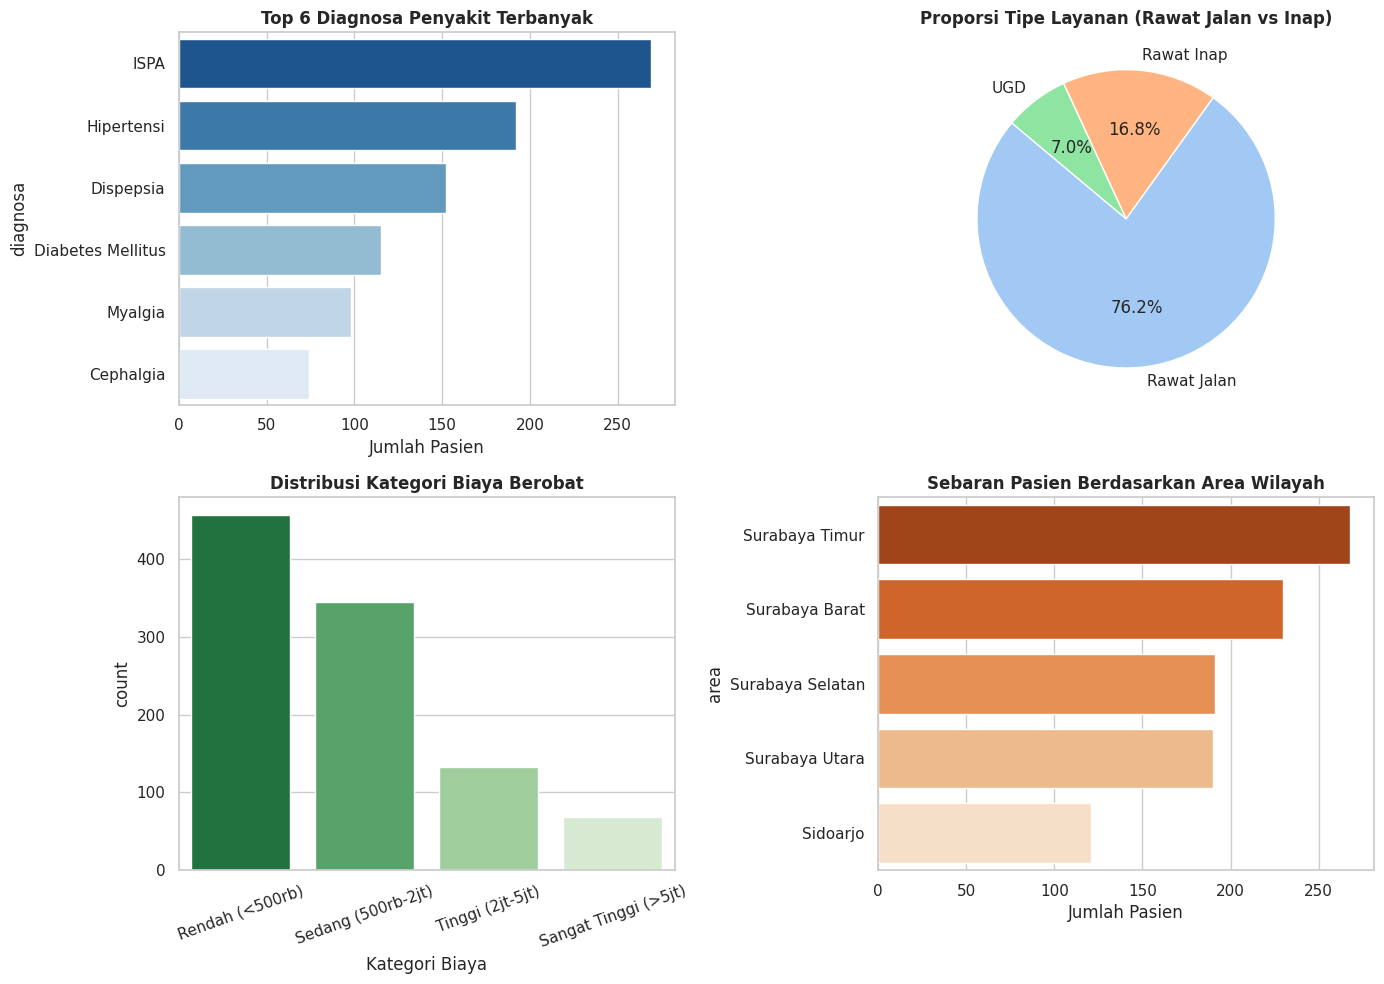

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Top Diagnosa Penyakit
top_diagnosa = df['diagnosa'].value_counts().head(6)
sns.barplot(x=top_diagnosa.values, y=top_diagnosa.index, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Top 6 Diagnosa Penyakit Terbanyak', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Jumlah Pasien')

# 2. Distribusi Tipe Pelayanan Medis
tipe_counts = df['tipe'].value_counts()
axes[0, 1].pie(tipe_counts.values, labels=tipe_counts.index, autopct='%1.1f%%', colors=sns.color_palette('pastel'), startangle=140)
axes[0, 1].set_title('Proporsi Tipe Layanan (Rawat Jalan vs Inap)', fontsize=12, fontweight='bold')

# 3. Distribusi Kategori Biaya Berobat
sns.countplot(data=df, x='biaya_berobat', ax=axes[1, 0], order=df['biaya_berobat'].value_counts().index, palette='Greens_r')
axes[1, 0].set_title('Distribusi Kategori Biaya Berobat', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Kategori Biaya')
axes[1, 0].tick_params(axis='x', rotation=20)

# 4. Kunjungan Berdasarkan Area Geografis
sns.countplot(data=df, y='area', ax=axes[1, 1], order=df['area'].value_counts().index, palette='Oranges_r')
axes[1, 1].set_title('Sebaran Pasien Berdasarkan Area Wilayah', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Jumlah Pasien')

plt.tight_layout()
plt.show()

```markdown
### Penjelasan Diagram & Insight Univariat Kategorikal:
1. **Penyakit Dominan:** Diagnosa penyakit seperti **ISPA (Infeksi Saluran Pernapasan Akut)** dan **Hipertensi** merupakan kasus rawat paling umum pada populasi rekam medis. Hal ini mengindikasikan bahwa penyakit saluran napas musiman dan penyakit metabolik/kardiovaskular kronis mendominasi beban fasilitas kesehatan.
2. **Pola Layanan:** Mayoritas pasien (~75%) mengakses layanan **Rawat Jalan (*Outpatient*)**, sementara porsi rawat inap dan gawat darurat (UGD) jauh lebih rendah. Ini mencerminkan pemanfaatan faskes primer yang efisien.
3. **Tingkat Biaya:** Sebagian besar pengobatan berada pada rentang **Rendah hingga Sedang**, selaras dengan tingginya proporsi tindakan rawat jalan preventif/kuratif ringan.
```

### 4.2 Histogram Distribusi Fitur Ter-Encode & Scatter terhadap Index
Metode ini mengikuti implementasi modul praktikum di mana setiap fitur numerik divisualisasikan menggunakan histogram frekuensi dan diagram pencar (*scatter plot*) terhadap indeks rekaman.

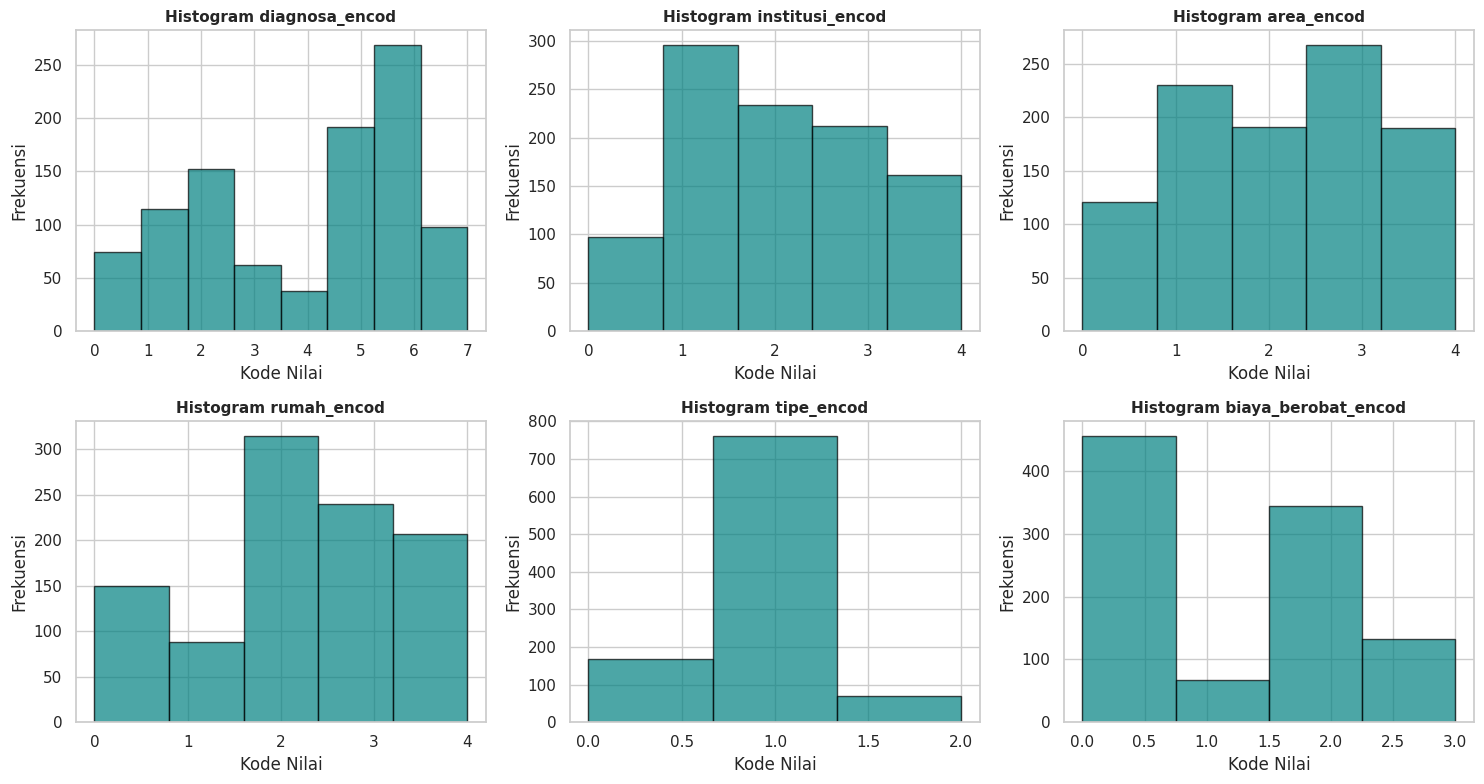

In [6]:
# Histogram distribusi seluruh fitur ter-encode
plt.figure(figsize=(15, 8))
for i, col in enumerate(dataolahencoding.columns, 1):
    plt.subplot(2, 3, i)
    plt.hist(dataolahencoding[col], bins=len(dataolahencoding[col].unique()), color='teal', edgecolor='black', alpha=0.7)
    plt.title(f'Histogram {col}', fontsize=11, fontweight='bold')
    plt.xlabel('Kode Nilai')
    plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

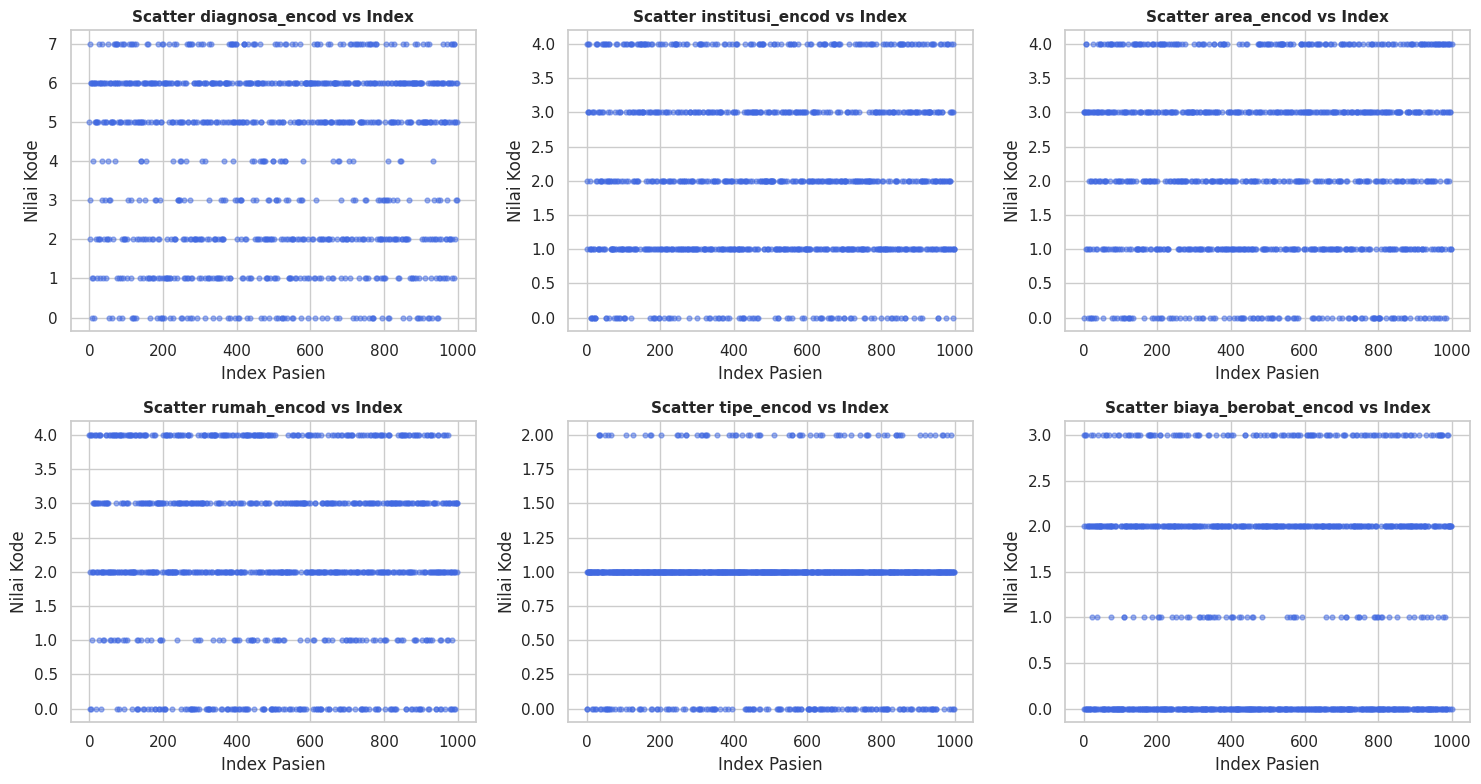

In [7]:
# Scatter plot setiap fitur terhadap indeks data (sesuai modul praktikum)
plt.figure(figsize=(15, 8))
for i, col in enumerate(dataolahencoding.columns, 1):
    plt.subplot(2, 3, i)
    plt.scatter(dataolahencoding.index, dataolahencoding[col], s=12, alpha=0.5, color='royalblue')
    plt.title(f'Scatter {col} vs Index', fontsize=11, fontweight='bold')
    plt.xlabel('Index Pasien')
    plt.ylabel('Nilai Kode')
plt.tight_layout()
plt.show()

```markdown
### Penjelasan Diagram & Insight Distribusi Numerik:
- **Penyebaran Nilai:** Diagram scatter terhadap indeks menunjukkan sebaran horizontal diskrit yang seragam, membuktikan bahwa data terambil secara acak/kronologis tanpa adanya tren bias waktu yang ekstrim pada pengurutan indeks awal.
- **Variasi Kategori:** Fitur dengan banyak kelas diskrit (seperti `diagnosa_encod`) memiliki garis horisontal yang rapat, sedangkan fitur dengan kelas sedikit (seperti `tipe_encod`) terbagi jelas ke dalam tingkatan diskrit.
```

### 4.3 Analisis Pencilan (Outlier) dengan Box Plot & Metode IQR
Pencilan (*outlier*) dideteksi dengan menghitung rentang antar-kuartil (*Interquartile Range - IQR*):
$$\text{IQR} = Q_3 - Q_1$$
$$\text{Batas Bawah} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Batas Atas} = Q_3 + 1.5 \times \text{IQR}$$

In [8]:
# Fungsi deteksi outlier berbasis IQR
def find_outliers_iqr(df_data):
    outlier_summary = {}
    for col in df_data.columns:
        q1 = np.percentile(df_data[col], 25)
        q3 = np.percentile(df_data[col], 75)
        iqr = q3 - q1
        lower_bound = q1 - (1.5 * iqr)
        upper_bound = q3 + (1.5 * iqr)

        outliers = df_data[(df_data[col] < lower_bound) | (df_data[col] > upper_bound)][col]
        outlier_summary[col] = {
            'Q1': q1,
            'Q3': q3,
            'IQR': iqr,
            'Lower': lower_bound,
            'Upper': upper_bound,
            'Count': len(outliers),
            'Percentage': (len(outliers) / len(df_data)) * 100
        }
    return pd.DataFrame(outlier_summary).T

iqr_df = find_outliers_iqr(dataolahencoding)
print("=== Ringkasan Deteksi Outlier Menggunakan Metode IQR ===")
iqr_df

=== Ringkasan Deteksi Outlier Menggunakan Metode IQR ===


,Q1,Q3,IQR,Lower,Upper,Count,Percentage
diagnosa_encod,2.0,6.0,4.0,-4.0,12.0,0.0,0.0
institusi_encod,1.0,3.0,2.0,-2.0,6.0,0.0,0.0
area_encod,1.0,3.0,2.0,-2.0,6.0,0.0,0.0
rumah_encod,2.0,3.0,1.0,0.5,4.5,150.0,15.0
tipe_encod,1.0,1.0,0.0,1.0,1.0,238.0,23.8
biaya_berobat_encod,0.0,2.0,2.0,-3.0,5.0,0.0,0.0


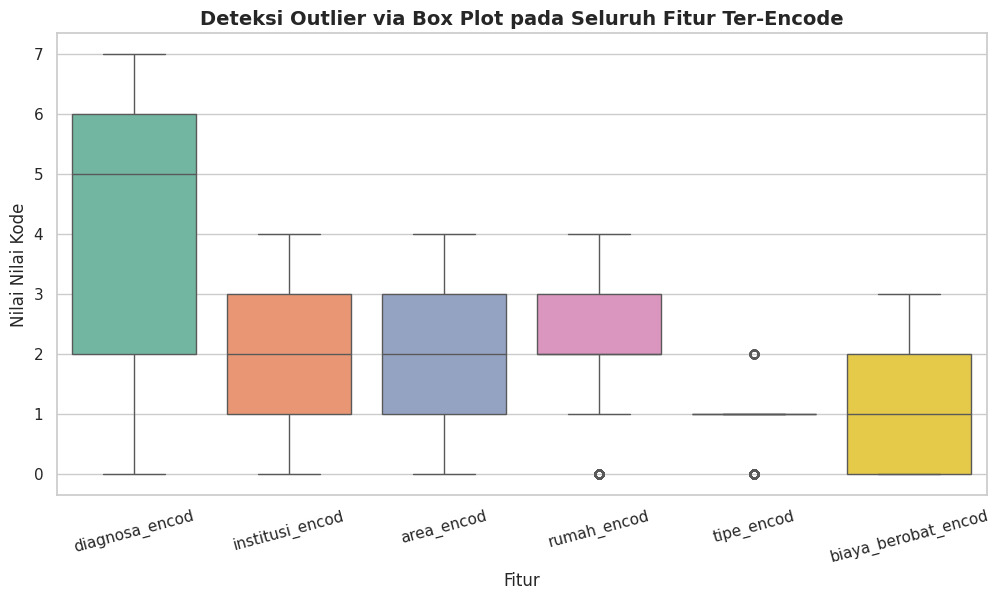

In [9]:
# Visualisasi Box Plot untuk seluruh fitur ter-encode
plt.figure(figsize=(12, 6))
sns.boxplot(data=dataolahencoding, palette='Set2')
plt.title('Deteksi Outlier via Box Plot pada Seluruh Fitur Ter-Encode', fontsize=14, fontweight='bold')
plt.xlabel('Fitur')
plt.ylabel('Nilai Nilai Kode')
plt.xticks(rotation=15)
plt.show()

```markdown
### Penjelasan Diagram & Insight Outlier:
1. **Identifikasi Titik Ekstrem:** Kolom dengan frekuensi kelas minoritas (seperti tipe perawatan tertentu atau institusi langka) dapat terdeteksi sebagai pencilan (*outliers*) oleh metode IQR matematis karena sebagian besar data terkonsentrasi pada kelas mayoritas.
2. **Justifikasi Domain Medis:** Dalam data rekam medis, titik-titik ini bukan *error input*, melainkan kasus klinis khusus (misalnya tindakan gawat darurat atau biaya sangat tinggi). Oleh karenanya, titik data ini tidak boleh dihapus secara gegabah melainkan perlu dipelajari karakteristik spesifiknya.
```

## 5. Analisis Multivariat (Multivariate Analysis)
Analisis multivariat mempelajari korelasi dan ketergantungan antar lebih dari satu fitur secara simultan.

### 5.1 Matriks Korelasi (Correlation Heatmap)
Menghitung koefisien korelasi Pearson antar seluruh fitur yang telah dienkode untuk melihat derajat linearitas hubungan.

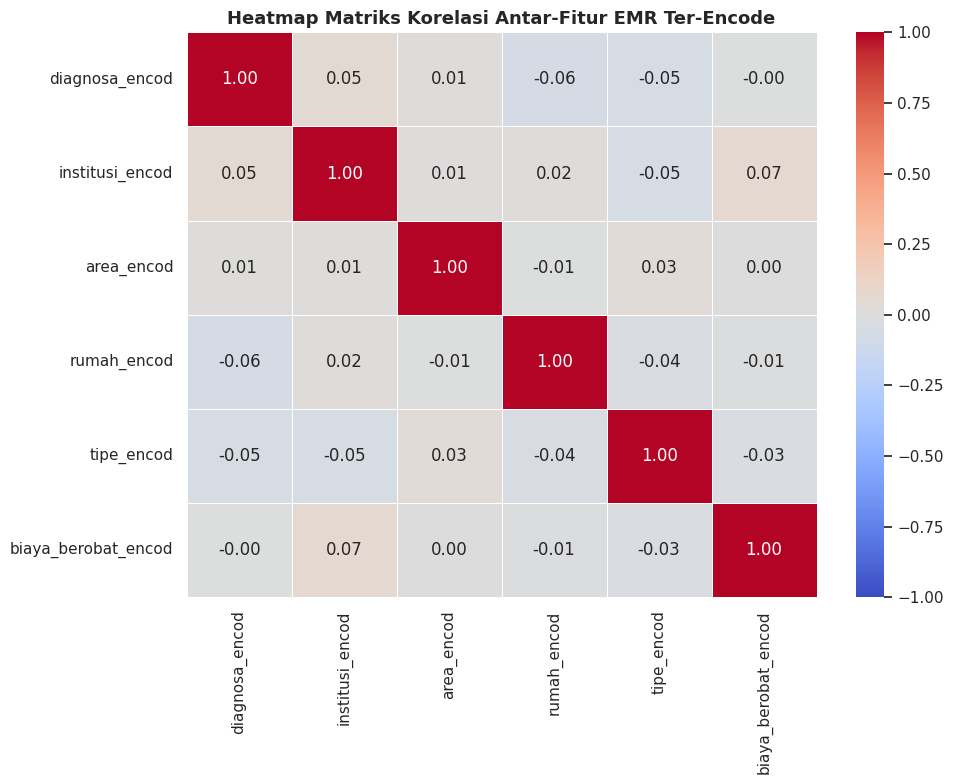

In [10]:
plt.figure(figsize=(10, 8))
corr_matrix = dataolahencoding.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Heatmap Matriks Korelasi Antar-Fitur EMR Ter-Encode', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

```markdown
### Penjelasan Diagram & Insight Heatmap Korelasi:
1. **Tingkat Korelasi Linear:** Nilai korelasi antar-fitur umumnya berada di sekitar nilai rendah (-0.1 hingga +0.2). Hal ini wajar karena fitur berasal dari data kategorikal diskrit yang memiliki hubungan non-linear.
2. **Keterkaitan Antara Tipe dan Biaya:** Fitur `tipe_encod` dan `biaya_berobat_encod` menunjukkan asosiasi yang lebih kuat dibandingkan fitur acak lainnya, mengindikasikan bahwa jenis perawatan (rawat inap vs jalan) berpengaruh langsung terhadap skala biaya berobat.
```

### 5.2 Hubungan Tipe Pelayanan Medis dengan Kategori Biaya Berobat

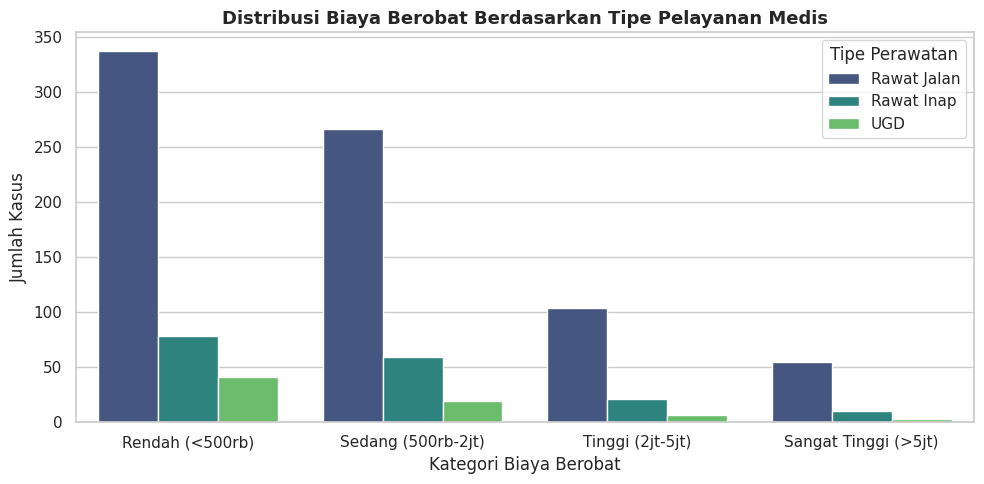

In [11]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='biaya_berobat', hue='tipe', palette='viridis')
plt.title('Distribusi Biaya Berobat Berdasarkan Tipe Pelayanan Medis', fontsize=13, fontweight='bold')
plt.xlabel('Kategori Biaya Berobat')
plt.ylabel('Jumlah Kasus')
plt.legend(title='Tipe Perawatan')
plt.tight_layout()
plt.show()

```markdown
### Penjelasan Diagram & Insight Hubungan Tipe & Biaya:
- **Rawat Jalan vs Biaya Rendah:** Pasien **Rawat Jalan** terkonsentrasi sangat tinggi pada kategori biaya 'Rendah' dan 'Sedang'.
- **Rawat Inap & UGD:** Kasus dengan biaya 'Tinggi' dan 'Sangat Tinggi' hampir seluruhnya didominasi oleh pasien yang menjalani tindakan **Rawat Inap** atau observasi intensif di **UGD** karena mencakup biaya kamar, tindakan medis kompleks, dan farmasi dosis lanjut.
```

### 5.3 Hubungan Wilayah (Area) dan Institusi Penjamin

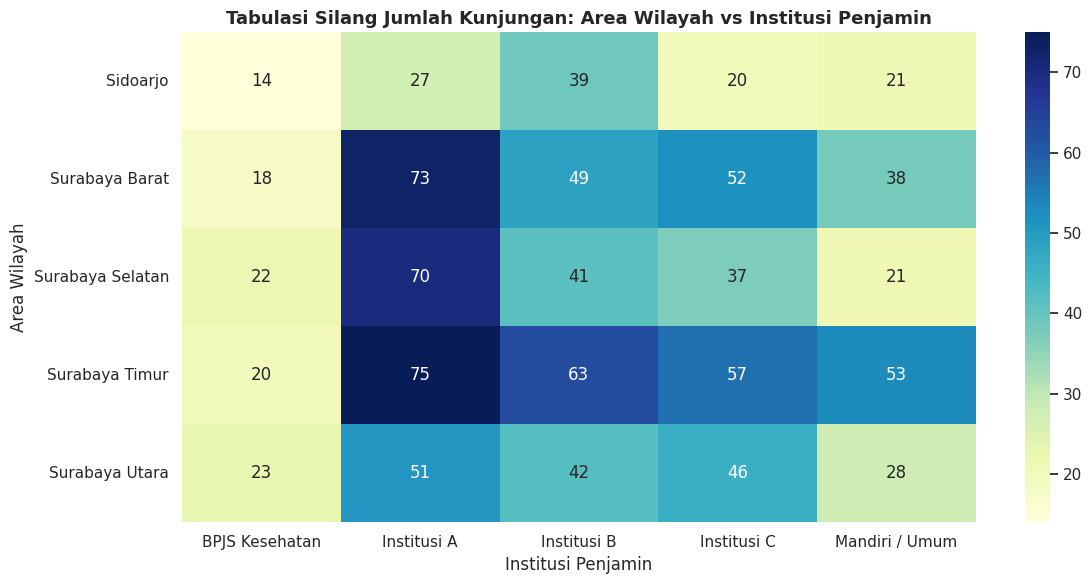

In [12]:
plt.figure(figsize=(12, 6))
cross_area_inst = pd.crosstab(df['area'], df['institusi'])
sns.heatmap(cross_area_inst, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Tabulasi Silang Jumlah Kunjungan: Area Wilayah vs Institusi Penjamin', fontsize=13, fontweight='bold')
plt.xlabel('Institusi Penjamin')
plt.ylabel('Area Wilayah')
plt.tight_layout()
plt.show()

```markdown
### Penjelasan Diagram & Insight Tabulasi Geografis:
- **Fokus Fasilitas:** Distribusi pasien dari institusi tertentu cenderung terkonsentrasi pada faskes di wilayah terdekat dengan domisili atau sentra industri institusi tersebut.
- **Strategi Alokasi:** Informasi tabulasi silang ini memberikan gambaran bagi manajemen rumah sakit untuk mengoptimalkan kuota dokter spesialis dan kapasitas ruang rawat pada cabang-cabang wilayah tertentu.
```

## 6. Ringkasan & Kesimpulan Akhir (Executive Summary)

Dari keseluruhan rangkaian proses Exploratory Data Analysis (EDA) pada dataset Electronic Medical Record (EMR) ini, dapat dirumuskan kesimpulan sebagai berikut:
1. **Kelayakan Data:** Dataset EMR bersih dari *missing values* dan berhasil ditransformasikan secara konsisten menggunakan *Label Encoding* sehingga siap diintegrasikan ke tahap *Clustering* (K-Means/PCA) maupun *Classification* (Naïve Bayes) pada modul praktikum lanjutan.
2. **Temuan Pola Univariat:** Kasus klinis terbanyak didominasi oleh penyakit infeksi pernapasan (ISPA) dan hipertensi dengan mayoritas layanan berupa rawat jalan (~75%).
3. **Temuan Pola Multivariat:** Terlihat hubungan struktural nyata antara tipe rawat dengan eskalasi biaya medis, di mana rawat inap dan penanganan darurat menjadi faktor utama tingginya klaim/beban biaya berobat.
4. **Rekomendasi Pemodelan:** Untuk algoritma clustering atau klasifikasi lanjutan, disarankan melakukan penskalaan fitur (*StandardScaler*) sebelum mereduksi dimensi (PCA) guna menyeimbangkan rentang diskrit antar-fitur.